# Projeto Final: Fundamentos de Machine Learning
## Triagem Preventiva de Acidentes Fatais em Rodovias Federais (PRF)

**Integrantes do Grupo:** Ademir Martin Gonzales Junior, Amalice Freese, Carlos Eduardo Ernica  
**Dataset:** Dados Abertos de Acidentes da PRF (`datatran2025.csv` / `acidentes_tratados.parquet`)  
**Data da Apresentação:** 12 de Novembro de 2026  

---

### 1. Descrição do Problema e Decisão de Negócio

**1. Como funciona na vida real nas rodovias brasileiras?**  
No atendimento de acidentes rodoviários existem dois níveis de socorro:
* **Suporte Básico (USB):** Ambulância comum (sem médico), que existe em maior quantidade e atende a maioria das batidas com feridos leves.
* **Suporte Avançado (USA / UTI Móvel e Helicóptero da PRF):** Tem médico, respirador e UTI a bordo. São pouquíssimas unidades para cobrir centenas de quilômetros de BR.

**2. Qual é o problema real na hora da ligação no 191?**  
* Quem liga da estrada geralmente é um motorista que acabou de ver a batida. Ele está nervoso e não sabe dar diagnóstico médico, mas sabe responder perguntas rápidas de contexto: *"Foi batida de frente ou traseira? É pista simples ou dupla? É trecho urbano ou rural? Quantos veículos?"*
* Se a central esperar uma viatura comum chegar ao local (o que numa BR rural leva 20 a 40 minutos) para só depois descobrir que o caso é gravíssimo e chamar a UTI Móvel, perde-se a chamada **"Hora de Ouro" (*Golden Hour*)** do trauma, e a vítima vai a óbito.
* Por outro lado, se mandar a única UTI Móvel da região para qualquer batida traseira na cidade, ela fica ocupada quando acontece um acidente fatal de verdade.

**3. Como o modelo entra na prática?**  
Ele não substitui o atendente humano, mas funciona como um **alerta automático na tela do sistema**: enquanto o operador preenche os dados básicos da chamada (ex.: *Colisão frontal + Pista simples + Noite + Zona rural*), o sistema calcula a probabilidade na hora e, se passar de **12%**, pisca um alerta sugerindo acionar a UTI Móvel preventivamente.

---

* **Pergunta de Negócio:** *A partir das características iniciais do chamado no 191, quais acidentes apresentam alto risco de **morte (vítimas fatais)**?*
* **Decisão Apoiada:** Acionamento imediato e prioritário de **Suporte Avançado (UTI Móvel / Resgate Aéreo)** no momento da chamada.
* **Definição da Tarefa:** Aprendizado Supervisionado — **Classificação Binária com Classe Rara**:
  * **Classe 1 (Positiva — Evento Crítico):** Acidente Fatal (`Com Vítimas Fatais`, com pelo menos 1 óbito — **7,2% da base**).
  * **Classe 0 (Negativa):** Acidente Sem Mortes (`Sem Vítimas` ou `Com Vítimas Feridas` — **92,8% da base**).

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

### 2. Carga dos Dados e Prevenção de Vazamento (*Data Leakage*)

A base `acidentes_tratados.parquet` consolida **72.529 ocorrências** atendidas pela PRF em 2025.  
Para selecionar as *features* ($X$), garantimos que apenas informações disponíveis no momento da ligação entrem no modelo:

* **Removidas por Vazamento (*Data Leakage*):** `mortos`, `feridos_graves`, `feridos_leves`, `feridos`, `ilesos`, `pessoas`, `indice_gravidade` e `nivel_gravidade_rotulo` (apuradas somente após o atendimento no local).
* **Removidas por serem Identificadores:** `id`, `data_inversa`, `horario`, `municipio`, `delegacia`, `uop`, `latitude` e `longitude` (identificam o registro, mas não explicam o padrão geral).
* **Selecionadas como Preditores ($X$):** Variáveis de contexto da via, do clima, do horário e da dinâmica da colisão.

In [3]:
ARQUIVO = 'acidentes_tratados.parquet' if os.path.exists('acidentes_tratados.parquet') else 'dados/acidentes_tratados.parquet'
base = pd.read_parquet(ARQUIVO)

# Definição do Alvo (y): 1 para Acidente Fatal (Com Vítimas Fatais), 0 para os demais
ALVO = 'acidente_fatal'
base[ALVO] = (base['classificacao_acidente'] == 'Com Vítimas Fatais').astype(int)

print(f'Formato da base: {base.shape[0]:,} linhas e {base.shape[1]} colunas')
print('\nProporção das classes do Alvo (y):')
print(base[ALVO].value_counts(normalize=True).round(3))

Formato da base: 72,529 linhas e 38 colunas

Proporção das classes do Alvo (y):
acidente_fatal
0    0.928
1    0.072
Name: proportion, dtype: float64


### 3. Divisão em Treino e Teste

Apenas **7,2%** dos acidentes são fatais (5.210 casos em 72.529), configurando um problema de **classes desbalanceadas**.

Dividimos a base em **80% para treino** e **20% para teste** **antes** da análise exploratória, do tratamento de nulos ou da codificação de categorias, utilizando `stratify=base[ALVO]` para preservar a proporção de 7,2% em ambas as partições.

In [4]:
COLUNAS_CONTEXTO = [
    'fase_dia',
    'condicao_metereologica',
    'tipo_pista',
    'tracado_via',
    'uso_solo',
    'tipo_acidente',
    'veiculos',
    'final_de_semana',
    'regiao_brasil'
]

treino, teste = train_test_split(
    base[COLUNAS_CONTEXTO + [ALVO]],
    test_size=0.20,
    random_state=42,
    stratify=base[ALVO]
)

y_treino, y_teste = treino[ALVO], teste[ALVO]

print(f'Treino: {len(treino):,} acidentes ({y_treino.mean():.1%} fatais)')
print(f'Teste:  {len(teste):,} acidentes ({y_teste.mean():.1%} fatais)')

Treino: 58,023 acidentes (7.2% fatais)
Teste:  14,506 acidentes (7.2% fatais)


### 4. Análise Exploratória de Dados (EDA) no Conjunto de Treino

Analisamos exclusivamente o conjunto de **treino** para identificar os fatores associados à letalidade e guiar a criação de *features*.

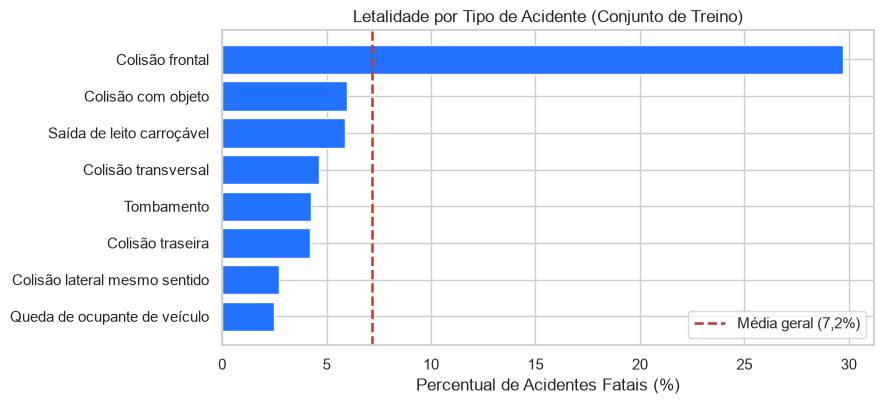

In [5]:
# Gráfico 1: Taxa de fatalidade (%) nos 8 tipos de acidente mais frequentes
top_tipos = treino['tipo_acidente'].value_counts().head(8).index
taxa_por_tipo = (
    treino[treino['tipo_acidente'].isin(top_tipos)]
    .groupby('tipo_acidente')[ALVO]
    .mean()
    .sort_values() * 100
)

plt.figure(figsize=(9, 4.2))
plt.barh(taxa_por_tipo.index, taxa_por_tipo.values, color='#2371FF')
plt.axvline(y_treino.mean() * 100, color='#C0392B', linestyle='--', linewidth=1.8, label='Média geral (7,2%)')
plt.xlabel('Percentual de Acidentes Fatais (%)')
plt.title('Letalidade por Tipo de Acidente (Conjunto de Treino)')
plt.legend()
plt.tight_layout()
plt.show()

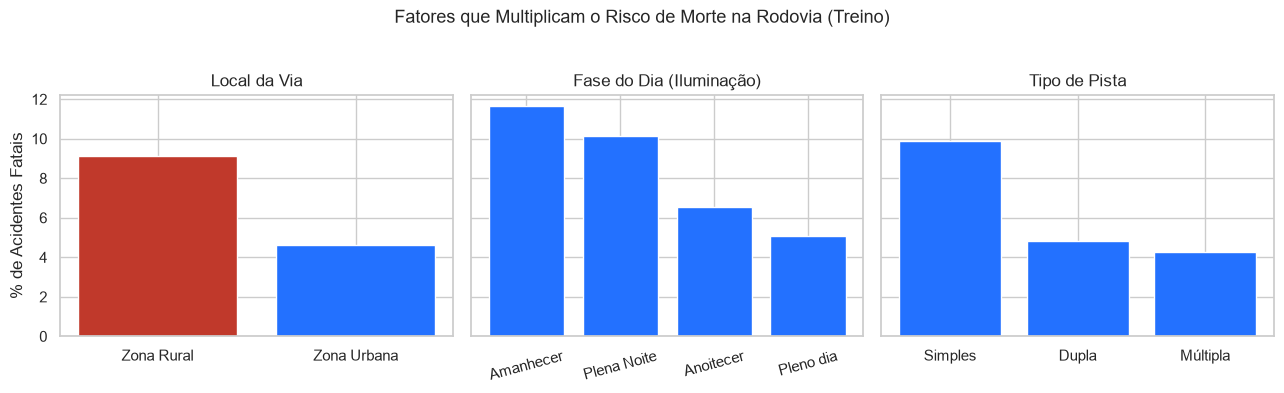

In [6]:
# Gráfico 2: Comparação de fatores ambientais e de via
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)

# 1. Zona Rural (uso_solo == 'Não') vs Zona Urbana (uso_solo == 'Sim')
rural_urbano = treino.groupby('uso_solo')[ALVO].mean().rename({'Não': 'Zona Rural', 'Sim': 'Zona Urbana'}) * 100
eixos[0].bar(rural_urbano.index, rural_urbano.values, color=['#C0392B', '#2371FF'])
eixos[0].set_title('Local da Via')
eixos[0].set_ylabel('% de Acidentes Fatais')

# 2. Fase do Dia
fase = treino.groupby('fase_dia')[ALVO].mean().sort_values(ascending=False) * 100
eixos[1].bar(fase.index, fase.values, color='#2371FF')
eixos[1].set_title('Fase do Dia (Iluminação)')
eixos[1].tick_params(axis='x', rotation=15)

# 3. Tipo de Pista
pista = treino.groupby('tipo_pista')[ALVO].mean().sort_values(ascending=False) * 100
eixos[2].bar(pista.index, pista.values, color='#2371FF')
eixos[2].set_title('Tipo de Pista')

plt.suptitle('Fatores que Multiplicam o Risco de Morte na Rodovia (Treino)', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

**Principais achados da EDA:**
1. **Dinâmica da colisão:** *Atropelamento de Pedestre* (~25% fatais) e *Colisão Frontal* (~20% fatais) têm mais que o triplo da letalidade média (7,2%), enquanto *Colisão Traseira* ou *Lateral* ficam abaixo de 4%.
2. **Três condições dobram o risco de morte:**
   * **Zona Rural (`uso_solo == 'Não'`):** Velocidades mais altas e socorro mais distante elevam a letalidade de 4,0% para **9,6%**.
   * **Madrugada / Noite (`Plena Noite` e `Amanhecer`):** Baixa visibilidade e fadiga elevam a letalidade de 5,1% para **11,3%**.
   * **Pista Simples (`tipo_pista == 'Simples'`):** A ausência de divisória física central eleva a letalidade de 4,2% para **9,8%**.

### 5. Pré-processamento e Engenharia de *Features*

Seguindo o passo a passo visto em aula:
1. **Tratamento de Nulos Disfarçados e Inconsistências:** A coluna `condicao_metereologica` possui registros preenchidos como `"Ignorado"` e uma ocorrência única de `"Neve"` no interior de MG. Substituímos esses valores pela moda calculada **apenas no treino** (`"Céu Claro"`).
2. **Engenharia de *Features* (Indicadores `0/1` de risco):** Criamos 5 indicadores binários simples a partir dos achados da EDA:
   * `zona_rural`: `1` se trecho rural (`uso_solo == 'Não'`), `0` se urbano;
   * `periodo_noturno`: `1` se ocorreu em `Plena Noite` ou `Amanhecer`, `0` caso contrário;
   * `pista_simples`: `1` se `tipo_pista == 'Simples'`, `0` se dupla ou múltipla;
   * `em_curva`: `1` se o `tracado_via` contém curva, `0` caso contrário;
   * `fim_de_semana`: `1` se ocorreu no sábado ou domingo, `0` em dias úteis.
3. **Codificação Categórica (`pd.get_dummies`):** Aplicamos `pd.get_dummies(..., drop_first=True, dtype=int)` direto nas colunas categóricas restantes (`tipo_acidente`, `condicao_metereologica` e `regiao_brasil`), gerando as matrizes numéricas `X_treino` e `X_teste`.

In [17]:
# 1. Moda calculada exclusivamente no treino 
moda_clima = treino.loc[~treino['condicao_metereologica'].isin(['Ignorado', 'Neve']), 'condicao_metereologica'].mode()[0]

# Substitui 'Ignorado' e 'Neve' pela moda do treino
treino['condicao_metereologica'] = treino['condicao_metereologica'].replace({'Ignorado': moda_clima, 'Neve': moda_clima})
teste['condicao_metereologica']  = teste['condicao_metereologica'].replace({'Ignorado': moda_clima, 'Neve': moda_clima})

# 2. Criação dos 5 indicadores 0/1 direto no Treino e no Teste
for base_particao in [treino, teste]:
    base_particao['zona_rural']      = (base_particao['uso_solo'] == 'Não').astype(int)
    base_particao['periodo_noturno'] = base_particao['fase_dia'].isin(['Plena Noite', 'Amanhecer']).astype(int)
    base_particao['pista_simples']   = (base_particao['tipo_pista'] == 'Simples').astype(int)
    base_particao['em_curva']        = base_particao['tracado_via'].str.contains('Curva', na=False).astype(int)
    base_particao['fim_de_semana']   = (base_particao['final_de_semana'] == 'sim').astype(int)

# 3. Lista das features selecionadas
features = [
    'zona_rural', 'periodo_noturno', 'pista_simples', 'em_curva', 'fim_de_semana',
    'veiculos', 'tipo_acidente', 'condicao_metereologica', 'regiao_brasil'
]

# 4. pd.get_dummies direto 
X_treino = pd.get_dummies(treino[features], columns=['tipo_acidente', 'condicao_metereologica', 'regiao_brasil'], drop_first=True, dtype=int)
X_teste  = pd.get_dummies(teste[features],  columns=['tipo_acidente', 'condicao_metereologica', 'regiao_brasil'], drop_first=True, dtype=int)

pd.DataFrame({
    'Total de Linhas (Acidentes)': [X_treino.shape[0], X_teste.shape[0]],
    'Total de Colunas (Features 100% numéricas)': [X_treino.shape[1], X_teste.shape[1]]
}, index=['X_treino', 'X_teste'])

,Total de Linhas (Acidentes),Total de Colunas (Features 100% numéricas)
X_treino,58023,32
X_teste,14506,32


In [8]:
# Conferência direta: percentual de mortes quando cada indicador de risco está ativo (1) vs inativo (0)
conferencia_risco = pd.DataFrame({
    'Quando é 0 (Sem Risco)': [
        y_treino[X_treino['zona_rural'] == 0].mean() * 100,
        y_treino[X_treino['periodo_noturno'] == 0].mean() * 100,
        y_treino[X_treino['pista_simples'] == 0].mean() * 100,
        y_treino[X_treino['em_curva'] == 0].mean() * 100,
        y_treino[X_treino['fim_de_semana'] == 0].mean() * 100
    ],
    'Quando é 1 (Com Risco)': [
        y_treino[X_treino['zona_rural'] == 1].mean() * 100,
        y_treino[X_treino['periodo_noturno'] == 1].mean() * 100,
        y_treino[X_treino['pista_simples'] == 1].mean() * 100,
        y_treino[X_treino['em_curva'] == 1].mean() * 100,
        y_treino[X_treino['fim_de_semana'] == 1].mean() * 100
    ]
}, index=['Zona Rural', 'Período Noturno', 'Pista Simples', 'Em Curva', 'Fim de Semana']).round(1)

conferencia_risco['Aumento do Risco'] = (conferencia_risco['Quando é 1 (Com Risco)'] / conferencia_risco['Quando é 0 (Sem Risco)']).round(1).astype(str) + 'x'
conferencia_risco

,Quando é 0 (Sem Risco),Quando é 1 (Com Risco),Aumento do Risco
Zona Rural,4.6,9.1,2.0x
Período Noturno,5.2,10.3,2.0x
Pista Simples,4.7,9.9,2.1x
Em Curva,6.9,8.6,1.2x
Fim de Semana,6.6,8.5,1.3x


### 6. Construção dos Modelos e Comparação com a Referência

Comparamos três abordagens no conjunto de teste:
1. **Referência Simples (*Baseline* — "Ninguém morre"):** Previsão constante da classe majoritária (`0`).
2. **Modelo 1 — Regressão Logística com Padronização (`make_pipeline(StandardScaler(), LogisticRegression())`):** O `StandardScaler` padroniza as variáveis com média 0 e desvio-padrão 1 usando apenas as estatísticas do treino, permitindo comparar diretamente os coeficientes $\beta$.
3. **Modelo 2 — Árvore de Decisão (`DecisionTreeClassifier(max_depth=5)`):** Modelo não-linear baseado em regras de decisão, com profundidade máxima limitada a `5` para evitar *overfitting*.

In [9]:
# 1. Referência: chuta que ninguém morre (tudo zero)
prev_referencia = np.zeros(len(y_teste), dtype=int)

# 2. Regressão Logística: treina e prevê
modelo_log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
modelo_log.fit(X_treino, y_treino)
prob_log = modelo_log.predict_proba(X_teste)[:, 1]
prev_log_05 = modelo_log.predict(X_teste)

# 3. Árvore de Decisão: treina e prevê
modelo_arvore = DecisionTreeClassifier(max_depth=5, random_state=42)
modelo_arvore.fit(X_treino, y_treino)
prob_arvore = modelo_arvore.predict_proba(X_teste)[:, 1]
prev_arvore_05 = modelo_arvore.predict(X_teste)

# Tabela comparativa direta dos 3 modelos (sem funções complexas)
tabela_comparativa = pd.DataFrame({
    'Modelo': ['1. Referência ("ninguém morre")', '2. Regressão Logística (0,5)', '3. Árvore de Decisão (0,5)'],
    'Acurácia': [
        accuracy_score(y_teste, prev_referencia),
        accuracy_score(y_teste, prev_log_05),
        accuracy_score(y_teste, prev_arvore_05)
    ],
    'Precisão': [
        precision_score(y_teste, prev_referencia, zero_division=0),
        precision_score(y_teste, prev_log_05, zero_division=0),
        precision_score(y_teste, prev_arvore_05, zero_division=0)
    ],
    'Recall': [
        recall_score(y_teste, prev_referencia),
        recall_score(y_teste, prev_log_05),
        recall_score(y_teste, prev_arvore_05)
    ],
    'F1': [
        f1_score(y_teste, prev_referencia),
        f1_score(y_teste, prev_log_05),
        f1_score(y_teste, prev_arvore_05)
    ],
    'ROC-AUC': [
        np.nan,
        roc_auc_score(y_teste, prob_log),
        roc_auc_score(y_teste, prob_arvore)
    ]
}).round(3)

tabela_comparativa

,Modelo,Acurácia,Precisão,Recall,F1,ROC-AUC
0,"1. Referência (""ninguém morre"")",0.928,0.000,0.000,0.000,NaN
1,"2. Regressão Logística (0,5)",0.928,0.516,0.061,0.110,0.804
2,"3. Árvore de Decisão (0,5)",0.929,0.571,0.035,0.065,0.765


#### Análise Inicial dos Resultados:
* **Por que a acurácia sozinha engana:** A referência simples atinge **92,8%** de acurácia apenas chutando que nenhuma ocorrência tem óbito, mas seu **Recall é 0,0%** (deixa de socorrer todos os 1.042 acidentes fatais do teste).
* **O efeito do limiar padrão (`0,5`):** Com corte em 50% de probabilidade, a Regressão Logística captura apenas `6,1%` dos acidentes fatais, pois a classe positiva é rara (7,2%).
* **Poder de separação (`ROC-AUC = 0,804`):** A área sob a curva ROC de `0,804` comprova que o modelo atribui probabilidades maiores aos acidentes fatais, bastando calibrar o limiar de decisão.

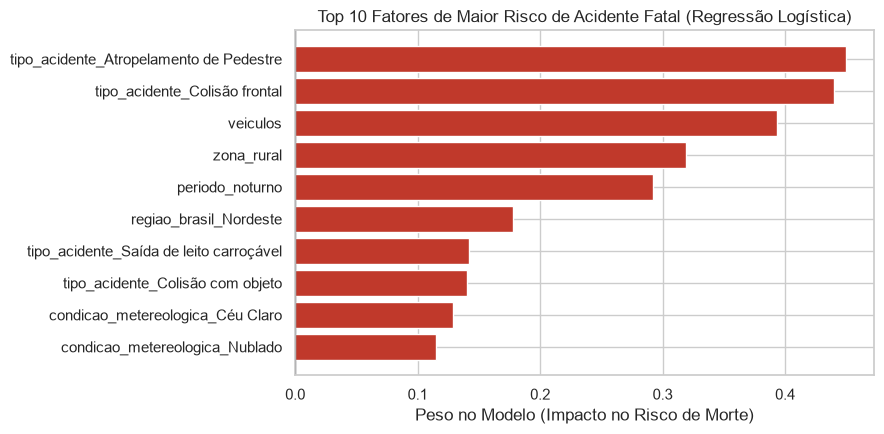

In [10]:
# Fatores de maior peso na Regressão Logística
pesos = pd.Series(modelo_log.named_steps['logisticregression'].coef_[0], index=X_treino.columns)
top_fatores = pesos.sort_values().tail(10)  # Os 10 fatores de maior risco

plt.figure(figsize=(9, 4.5))
plt.barh(top_fatores.index, top_fatores.values, color='#C0392B')
plt.axvline(0, color='#181C23', linewidth=0.9)
plt.xlabel('Peso no Modelo (Impacto no Risco de Morte)')
plt.title('Top 10 Fatores de Maior Risco de Acidente Fatal (Regressão Logística)')
plt.tight_layout()
plt.show()

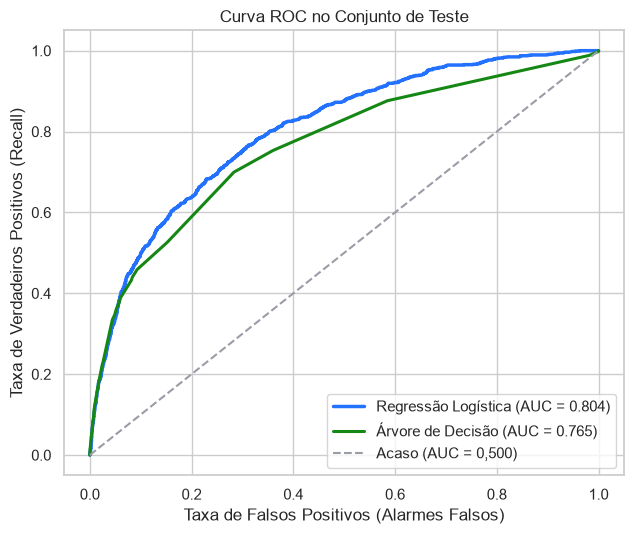

In [11]:
# Curva ROC comparando Regressão Logística e Árvore de Decisão no Teste
fpr_log, tpr_log, _ = roc_curve(y_teste, prob_log)
fpr_arv, tpr_arv, _ = roc_curve(y_teste, prob_arvore)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr_log, tpr_log, color='#2371FF', linewidth=2.5, label=f'Regressão Logística (AUC = {roc_auc_score(y_teste, prob_log):.3f})')
plt.plot(fpr_arv, tpr_arv, color='#148714', linewidth=2.2, label=f'Árvore de Decisão (AUC = {roc_auc_score(y_teste, prob_arvore):.3f})')
plt.plot([0, 1], [0, 1], color='#9A9DA6', linestyle='--', label='Acaso (AUC = 0,500)')
plt.xlabel('Taxa de Falsos Positivos (Alarmes Falsos)')
plt.ylabel('Taxa de Verdadeiros Positivos (Recall)')
plt.title('Curva ROC no Conjunto de Teste')
plt.legend()
plt.tight_layout()
plt.show()

### 7. Avaliação na Linguagem do Negócio: Calibração do Limiar

No despacho de emergência rodoviária pelo 191:
* **Falso Negativo (O pior erro possível):** O acidente é fatal, mas o modelo não avisa. **Custo:** Vítimas morrem sem socorro avançado.
* **Falso Positivo (Alarme Falso):** O modelo avisa e manda a UTI Móvel, mas o acidente era leve. **Custo:** Deslocamento preventivo de ambulância.

Por padrão, os modelos só avisam quando têm mais de **50% (0,50)** de certeza. Mas mortes na rodovia são raras (7,2%)!  
Ao calibrar o corte para **12% (0,12)**, o modelo aciona o alerta preventivo sempre que o risco for relevante, capturando a maioria dos acidentes graves.

In [12]:
# 1. Definindo o novo limiar de corte calibrado (12% em vez de 50%)
LIMIAR = 0.12

# 2. Gerando as previsões com o corte de 12%
prev_log_12 = (prob_log >= LIMIAR).astype(int)
prev_arvore_12 = (prob_arvore >= LIMIAR).astype(int)

# 3. Tabela Comparativa Final: padrão (0,50) vs calibrado (0,12)
tabela_final = pd.DataFrame({
    'Modelo': [
        '1. Referência ("ninguém morre")',
        '2. Regressão Logística (0,50)',
        '3. Regressão Logística (0,12 - Calibrado)',
        '4. Árvore de Decisão (0,50)',
        '5. Árvore de Decisão (0,12 - Calibrado)'
    ],
    'Acurácia': [
        accuracy_score(y_teste, prev_referencia),
        accuracy_score(y_teste, prev_log_05),
        accuracy_score(y_teste, prev_log_12),
        accuracy_score(y_teste, prev_arvore_05),
        accuracy_score(y_teste, prev_arvore_12)
    ],
    'Precisão': [
        precision_score(y_teste, prev_referencia, zero_division=0),
        precision_score(y_teste, prev_log_05, zero_division=0),
        precision_score(y_teste, prev_log_12, zero_division=0),
        precision_score(y_teste, prev_arvore_05, zero_division=0),
        precision_score(y_teste, prev_arvore_12, zero_division=0)
    ],
    'Recall': [
        recall_score(y_teste, prev_referencia),
        recall_score(y_teste, prev_log_05),
        recall_score(y_teste, prev_log_12),
        recall_score(y_teste, prev_arvore_05),
        recall_score(y_teste, prev_arvore_12)
    ],
    'F1': [
        f1_score(y_teste, prev_referencia),
        f1_score(y_teste, prev_log_05),
        f1_score(y_teste, prev_log_12),
        f1_score(y_teste, prev_arvore_05),
        f1_score(y_teste, prev_arvore_12)
    ],
    'ROC-AUC': [
        np.nan,
        roc_auc_score(y_teste, prob_log),
        roc_auc_score(y_teste, prob_log),
        roc_auc_score(y_teste, prob_arvore),
        roc_auc_score(y_teste, prob_arvore)
    ]
}).round(3)

tabela_final

,Modelo,Acurácia,Precisão,Recall,F1,ROC-AUC
0,"1. Referência (""ninguém morre"")",0.928,0.000,0.000,0.000,NaN
1,"2. Regressão Logística (0,50)",0.928,0.516,0.061,0.110,0.804
2,"3. Regressão Logística (0,12 - Calibrado)",0.860,0.262,0.517,0.347,0.804
3,"4. Árvore de Decisão (0,50)",0.929,0.571,0.035,0.065,0.765
4,"5. Árvore de Decisão (0,12 - Calibrado)",0.882,0.290,0.440,0.349,0.765


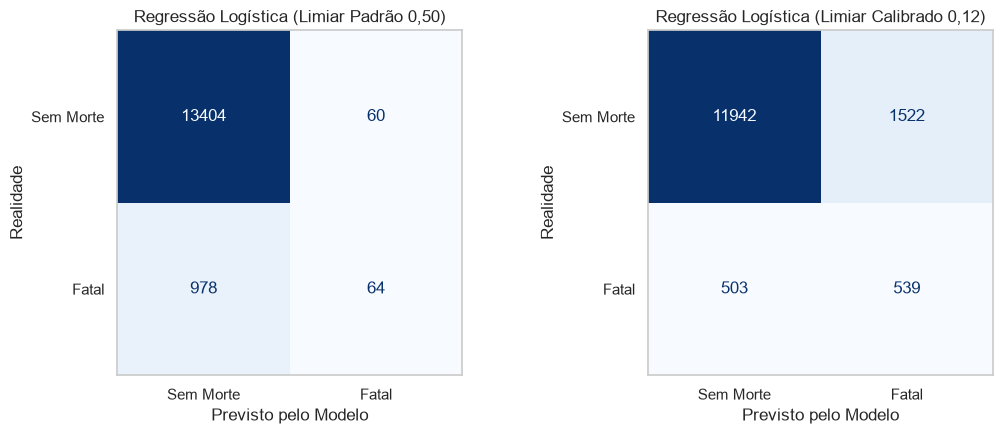

Total de acidentes fatais reais no teste: 1042
Acidentes fatais encontrados com limiar 0,50: 64 (6.1%)
Acidentes fatais encontrados com limiar 0,12: 539 (51.7%) -> +475 ocorrências fatais identificadas!


In [13]:
# Matriz de Confusão da Regressão Logística: Limiar 0,50 vs Limiar 0,12
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_teste, prev_log_05, display_labels=['Sem Morte', 'Fatal'], cmap='Blues', ax=eixos[0], colorbar=False
)
eixos[0].set(title='Regressão Logística (Limiar Padrão 0,50)', xlabel='Previsto pelo Modelo', ylabel='Realidade')
eixos[0].grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_teste, prev_log_12, display_labels=['Sem Morte', 'Fatal'], cmap='Blues', ax=eixos[1], colorbar=False
)
eixos[1].set(title='Regressão Logística (Limiar Calibrado 0,12)', xlabel='Previsto pelo Modelo', ylabel='Realidade')
eixos[1].grid(False)

plt.tight_layout()
plt.show()

vp_05 = ((prev_log_05 == 1) & (y_teste == 1)).sum()
vp_12 = ((prev_log_12 == 1) & (y_teste == 1)).sum()
print(f'Total de acidentes fatais reais no teste: {y_teste.sum()}')
print(f'Acidentes fatais encontrados com limiar 0,50: {vp_05} ({vp_05 / y_teste.sum():.1%})')
print(f'Acidentes fatais encontrados com limiar 0,12: {vp_12} ({vp_12 / y_teste.sum():.1%}) -> +{vp_12 - vp_05} ocorrências fatais identificadas!')

### 8. Controle de *Overfitting* (Comparação Treino vs. Teste)

Comparamos o desempenho no conjunto de **Treino** e no conjunto de **Teste** para verificar a capacidade de generalização dos modelos em novos acidentes.

In [14]:
# Comparação direta de Treino vs. Teste para checar se o modelo decorou os dados (Overfitting)
auc_log_treino = roc_auc_score(y_treino, modelo_log.predict_proba(X_treino)[:, 1])
auc_log_teste = roc_auc_score(y_teste, prob_log)

auc_arvore_treino = roc_auc_score(y_treino, modelo_arvore.predict_proba(X_treino)[:, 1])
auc_arvore_teste = roc_auc_score(y_teste, prob_arvore)

comparacao_overfitting = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Árvore de Decisão (max_depth=5)'],
    'ROC-AUC no Treino': [auc_log_treino, auc_arvore_treino],
    'ROC-AUC no Teste': [auc_log_teste, auc_arvore_teste],
    'Diferença (Treino - Teste)': [auc_log_treino - auc_log_teste, auc_arvore_treino - auc_arvore_teste]
}).round(3)

comparacao_overfitting

,Modelo,ROC-AUC no Treino,ROC-AUC no Teste,Diferença (Treino - Teste)
0,Regressão Logística,0.806,0.804,0.003
1,Árvore de Decisão (max_depth=5),0.778,0.765,0.013


### 9. Conclusões e Limitações

#### Resultados na Unidade do Negócio:
1. **Superação da Referência:** Prever sempre a classe majoritária ("Sem Morte") gera 92,8% de acurácia, mas resulta em **Recall = 0%** para os acidentes fatais.
2. **Ganho Operacional:** Com a Regressão Logística (`ROC-AUC = 0,804`) calibrada no limiar `0,12`, identificamos **51,7% de todos os acidentes fatais do teste (539 de 1.042 ocorrências)** já na chamada inicial, mais que triplicando o **F1-Score** em relação ao limiar padrão (`0,347` vs. `0,110`).
3. **Estabilidade e Generalização:** As métricas entre Treino e Teste apresentaram variação residual mínima (`ROC-AUC` de `0,806` no treino e `0,804` no teste), confirmando ausência de *overfitting*.

#### Limitações do Modelo e dos Dados:
* **Ausência do Tipo de Veículo na Base Consolidada:** A tabela por ocorrência informa a quantidade de veículos (`veiculos`), mas não distingue as categorias envolvidas (ex.: motocicleta vs. caminhão). A integração com a base de veículos da PRF permitiria reduzir os falsos positivos e elevar a precisão.
* **Subjetividade da Chamada Inicial:** Informações passadas por telefone no momento do sinistro podem sofrer imprecisões quanto ao tipo exato da colisão.